# 04 — Retrieval and validation against truth

Runs `retrieve_lwc_zhu` unchanged, then compares against the PAMTRA input LWC.

The central plot is error against cloud thickness. Thin clouds force a small
window (`N = min(N_default, thickness)`), and single-window error scales as
N^-3/2, so performance should degrade sharply for thin cloud. The sweep over 54
thicknesses tests exactly that.

In [1]:
import sys
from pathlib import Path

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

sys.path.append(str(Path("../src").resolve()))
from radar_lwc.retrieval.zhu import retrieve_lwc_zhu

DATA_DIR = Path("../data/processed/pamtra_test_1")
ds_retrieval = xr.open_dataset(DATA_DIR / "retrieval_input.nc")

In [2]:
#ds_retrieval.close()

In [3]:
N_DEFAULT = 9

lwc, derivative, m_eff, n_windows, n_used = retrieve_lwc_zhu(
    dwr=ds_retrieval["DWR"],
    kappa_w=ds_retrieval["kappa_W"],
    kappa_ka=ds_retrieval["kappa_Ka"],
    alpha_w=ds_retrieval["alpha_W"],
    alpha_ka=ds_retrieval["alpha_Ka"],
    cloud_mask=ds_retrieval["cloud_mask"],
    N_default=N_DEFAULT,
)

lwc_true = ds_retrieval["LWC_true"]
mask = ds_retrieval["cloud_mask"] & lwc.notnull() & (lwc_true > 0)

print(f"retrieved gates : {int(lwc.notnull().sum())}")
print(f"comparable gates: {int(mask.sum())}")
print(f"fraction LWC<0  : {float((lwc < 0).sum() / lwc.notnull().sum()):.2%}")

retrieved gates : 1375
comparable gates: 1375
fraction LWC<0  : 0.00%


## Overall agreement

In [4]:
r = lwc.where(mask).values.ravel()
t = lwc_true.where(mask).values.ravel()
ok = np.isfinite(r) & np.isfinite(t)
r, t = r[ok], t[ok]

bias = np.mean(r - t)
rmse = np.sqrt(np.mean((r - t) ** 2))
corr = np.corrcoef(r, t)[0, 1]

print(f"n     : {r.size}")
print(f"bias  : {bias:+.4f} g/m3")
print(f"RMSE  : {rmse:.4f} g/m3")
print(f"corr  : {corr:.4f}")
print(f"mean true LWC: {t.mean():.4f} g/m3")
print(f"relative RMSE: {rmse / t.mean():.1%}")

n     : 1375
bias  : +0.0555 g/m3
RMSE  : 0.0622 g/m3
corr  : 0.9947
mean true LWC: 0.5164 g/m3
relative RMSE: 12.0%


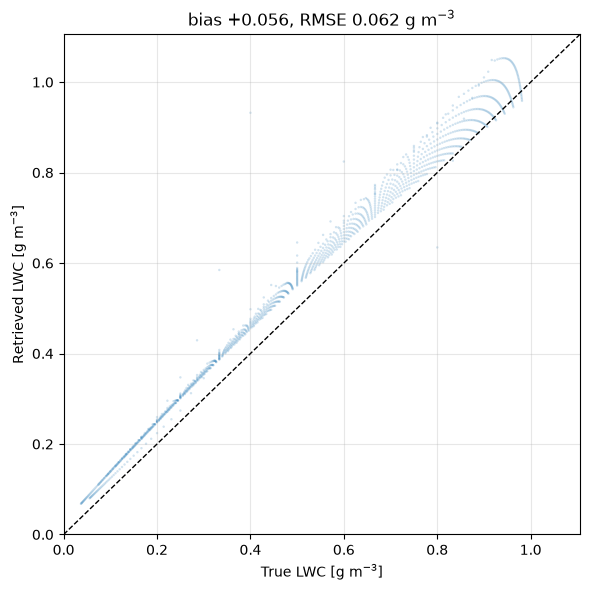

In [5]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(t, r, s=3, alpha=0.2, edgecolors="none")
lim = [0, max(t.max(), r.max()) * 1.05]
ax.plot(lim, lim, "k--", lw=1)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("True LWC [g m$^{-3}$]")
ax.set_ylabel("Retrieved LWC [g m$^{-3}$]")
ax.set_title(f"bias {bias:+.3f}, RMSE {rmse:.3f} g m$^{{-3}}$")
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Error vs cloud thickness

This is the key diagnostic.

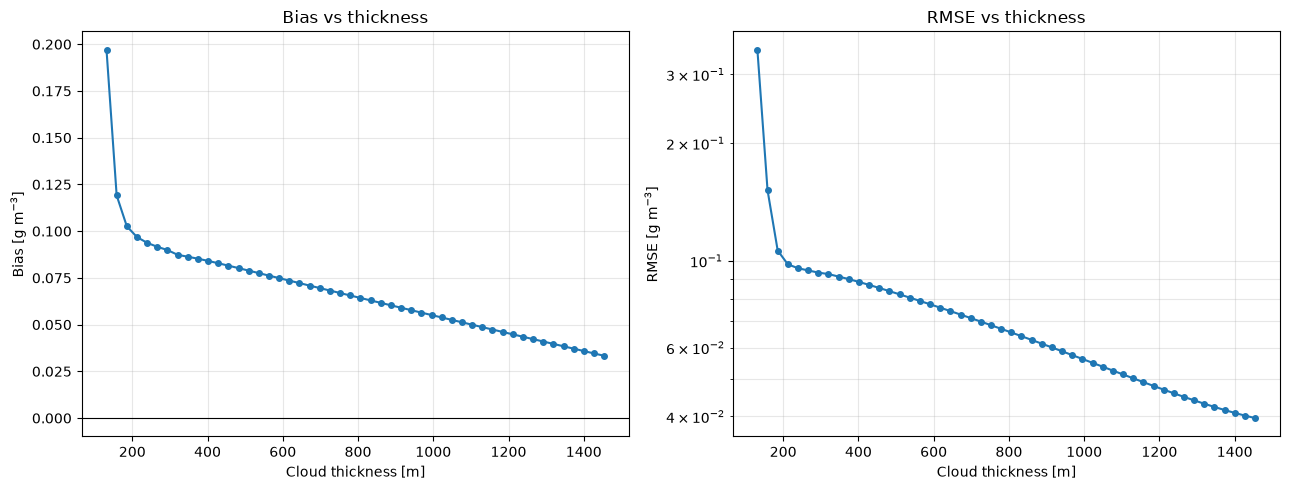

Window size actually used, by scene:
  thickness    22.4 m -> N = 0
  thickness   158.4 m -> N = 4
  thickness   293.4 m -> N = 9
  thickness   563.4 m -> N = 9
  thickness  1103.4 m -> N = 9
  thickness  1454.4 m -> N = 9


In [6]:
diff = (lwc - lwc_true).where(mask)
per_scene_bias = diff.mean("range")
per_scene_rmse = np.sqrt((diff ** 2).mean("range"))
thick = ds_retrieval["cloud_thickness"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(thick, per_scene_bias, "o-", ms=4)
axes[0].axhline(0, color="k", lw=0.8)
axes[0].set_xlabel("Cloud thickness [m]"); axes[0].set_ylabel("Bias [g m$^{-3}$]")
axes[0].set_title("Bias vs thickness"); axes[0].grid(alpha=0.3)

axes[1].plot(thick, per_scene_rmse, "o-", ms=4)
axes[1].set_xlabel("Cloud thickness [m]"); axes[1].set_ylabel("RMSE [g m$^{-3}$]")
axes[1].set_yscale("log"); axes[1].set_title("RMSE vs thickness")
axes[1].grid(alpha=0.3, which="both")

plt.tight_layout(); plt.show()

print("Window size actually used, by scene:")
for i in [0, 5, 10, 20, 40, 53]:
    print(f"  thickness {float(thick[i]):7.1f} m -> N = {int(n_used[i])}")

## Profile comparison

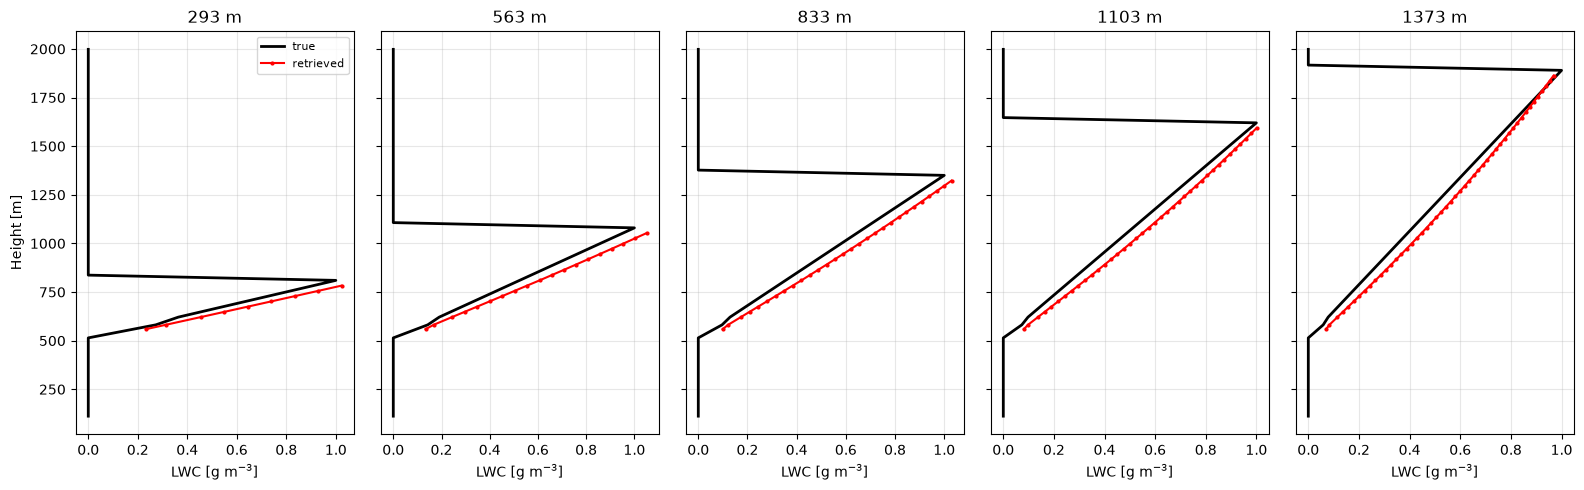

In [7]:
scenes = [10, 20, 30, 40, 50]
fig, axes = plt.subplots(1, len(scenes), figsize=(16, 5), sharey=True)

for ax, t_i in zip(axes, scenes):
    ax.plot(lwc_true.isel(Time=t_i), ds_retrieval.range, "k-", lw=2, label="true")
    ax.plot(lwc.isel(Time=t_i), ds_retrieval.range, "r.-", ms=4, label="retrieved")
    ax.set_title(f"{float(thick[t_i]):.0f} m")
    ax.set_xlabel("LWC [g m$^{-3}$]"); ax.grid(alpha=0.3)

axes[0].set_ylabel("Height [m]"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## LWP closure

Integrating removes the vertical-structure question and tests the column total,
which is what a microwave radiometer would measure.

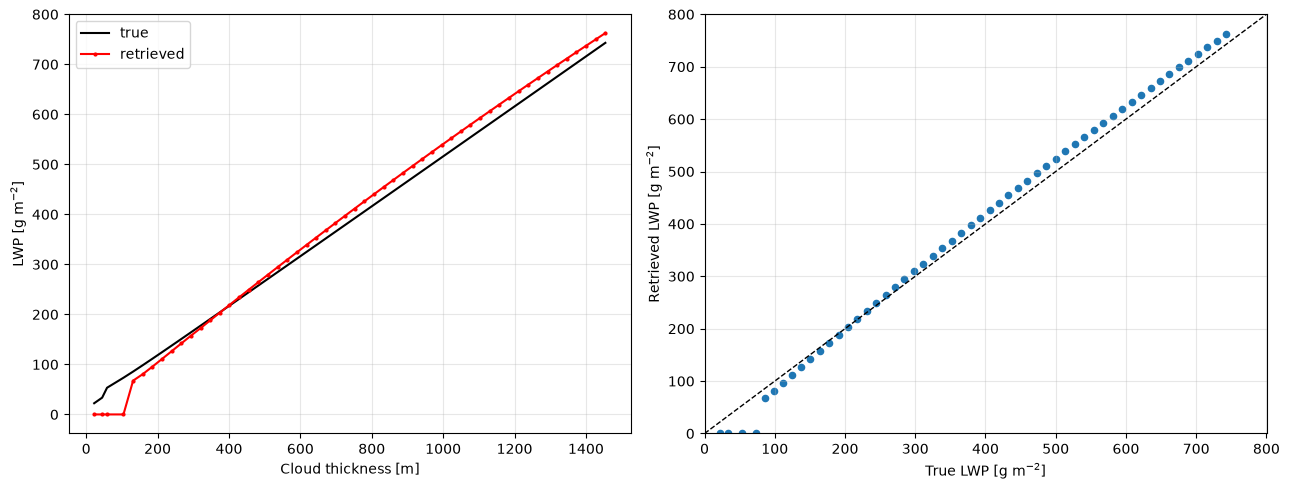

median relative LWP error: +3.6%


In [8]:
dz = np.gradient(ds_retrieval.range.values)
dz_da = xr.DataArray(dz, dims=["range"], coords={"range": ds_retrieval.range})

lwp_true = (lwc_true.fillna(0) * dz_da).sum("range")
lwp_ret  = (lwc.where(mask).fillna(0) * dz_da ).sum("range")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(thick, lwp_true, "k-", label="true")
axes[0].plot(thick, lwp_ret, "r.-", ms=4, label="retrieved")
axes[0].set_xlabel("Cloud thickness [m]"); axes[0].set_ylabel("LWP [g m$^{-2}$]")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].scatter(lwp_true, lwp_ret, s=20)
lim = [0, float(max(lwp_true.max(), lwp_ret.max())) * 1.05]
axes[1].plot(lim, lim, "k--", lw=1)
axes[1].set_xlim(lim); axes[1].set_ylim(lim)
axes[1].set_xlabel("True LWP [g m$^{-2}$]"); axes[1].set_ylabel("Retrieved LWP [g m$^{-2}$]")
axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

rel = ((lwp_ret - lwp_true) / lwp_true).where(lwp_true > 1)
print(f"median relative LWP error: {float(rel.median()):+.1%}")

In [9]:
out = xr.Dataset({
    "LWC_retrieved": lwc,
    "LWC_true": lwc_true,
    "dDWR_dh": derivative,
    "M_eff": m_eff,
    "n_windows": n_windows,
    "N_used": n_used,
    "LWP_true": lwp_true,
    "LWP_retrieved": lwp_ret,
}, attrs={"N_default": N_DEFAULT, "created_by": "04_retrieval_validation.ipynb"})

out.to_netcdf(DATA_DIR / "retrieval_output.nc")
print("Saved -> retrieval_output.nc")

Saved -> retrieval_output.nc
